# 大学生恋爱数据分析

1.结婚意愿和自身性别的关系

2.认为婚后男女风险大小和自身性别的关系

3.异性恋和同性恋者对于结婚意愿和婚后风险大小的认知区别

## 数据准备

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
# 设置字体
plt.rcParams["font.sans-serif"]=["SimHei"]
# 该语句解决图像中的“-”负号的乱码问题
plt.rcParams["axes.unicode_minus"]=False
import seaborn as sns

### 读取数据

In [2]:
# 如果找不到文件就转为相对路径
data=pd.read_excel('大学生婚姻分析.xlsx')
data.head()

,1、您的年龄？,2、您的性别,3、您的年级？,4、您的性取向,5、您是否有结婚倾向（是否向往婚姻）,6、您向往/不向往婚姻的理由是什么？（选答）,7、您认为在婚姻中男性承担的风险大还是女性承担的风险大？（5分为认为同等大）,8、您认为女性比男性多承担了哪些风险（若是两性都有，但是女性更多也可以选择）,9、您认为男性比女性多承担了哪些风险（若是两性都有，但是男性更多也可以选择）,总分
0,19,男,大二,异性恋,5,无感,女性风险大,家庭妇女的心理困境风险┋身体健康风险（针对一些重大疾病）┋婚姻满意度低的风险┋对方出轨风险,(跳过),15
1,18,男,大一,异性恋,6,(空),7,家庭妇女的心理困境风险┋职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）,(跳过),13
2,23,女,硕士研究生,异性恋,6,(空),9,产后抑郁风险┋职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）┋婚姻满意度...,(跳过),15
3,19,女,大二,异性恋,7,(空),9,家庭妇女的心理困境风险┋身体健康风险（针对一些重大疾病）┋产后抑郁风险┋职业女性观念冲突风险...,(跳过),16
4,19,女,大二,异性恋,4,(空),女性风险大,家庭妇女的心理困境风险┋身体健康风险（针对一些重大疾病）┋产后抑郁风险┋职业女性观念冲突风险...,(跳过),14


### 清洗数据

修改数据的列标题

In [3]:
data.columns=['年龄','性别','年级','性取向','结婚倾向','结婚理由','风险比较','女性风险大的原因','男性风险大的原因','总分']
data.head()

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分
0,19,男,大二,异性恋,5,无感,女性风险大,家庭妇女的心理困境风险┋身体健康风险（针对一些重大疾病）┋婚姻满意度低的风险┋对方出轨风险,(跳过),15
1,18,男,大一,异性恋,6,(空),7,家庭妇女的心理困境风险┋职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）,(跳过),13
2,23,女,硕士研究生,异性恋,6,(空),9,产后抑郁风险┋职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）┋婚姻满意度...,(跳过),15
3,19,女,大二,异性恋,7,(空),9,家庭妇女的心理困境风险┋身体健康风险（针对一些重大疾病）┋产后抑郁风险┋职业女性观念冲突风险...,(跳过),16
4,19,女,大二,异性恋,4,(空),女性风险大,家庭妇女的心理困境风险┋身体健康风险（针对一些重大疾病）┋产后抑郁风险┋职业女性观念冲突风险...,(跳过),14


“结婚倾向”一列在做问卷的时候有问题：完全不想结婚是0，非常想结婚是10，但问卷结果表格里面的数据是文字。把这些变成数值。

同理风险比较那一栏，“男性风险大”是0，“女性风险大”是10，但问卷结果表格里面的数据是文字，把这些变成数值。

In [4]:
# 结婚倾向那一栏
data.loc[data['结婚倾向']=='完全不想结婚',['结婚倾向']]=0
data.loc[data['结婚倾向']=='非常想结婚',['结婚倾向']]=10
# 风险比较那一栏
data.loc[data['风险比较']=='女性风险大',['风险比较']]=10
data.loc[data['风险比较']=='男性风险大',['风险比较']]=0
data

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分
0,19,男,大二,异性恋,5,无感,10,家庭妇女的心理困境风险┋身体健康风险（针对一些重大疾病）┋婚姻满意度低的风险┋对方出轨风险,(跳过),15
1,18,男,大一,异性恋,6,(空),7,家庭妇女的心理困境风险┋职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）,(跳过),13
2,23,女,硕士研究生,异性恋,6,(空),9,产后抑郁风险┋职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）┋婚姻满意度...,(跳过),15
3,19,女,大二,异性恋,7,(空),9,家庭妇女的心理困境风险┋身体健康风险（针对一些重大疾病）┋产后抑郁风险┋职业女性观念冲突风险...,(跳过),16
4,19,女,大二,异性恋,4,(空),10,家庭妇女的心理困境风险┋身体健康风险（针对一些重大疾病）┋产后抑郁风险┋职业女性观念冲突风险...,(跳过),14
...,...,...,...,...,...,...,...,...,...,...
166,20,男,大一,异性恋,9,(空),7,身体健康风险（针对一些重大疾病）┋产后抑郁风险┋职业女性观念冲突风险（例如：家务分工观念风险...,(跳过),16
167,21,男,大三,异性恋,1,(空),5,(跳过),(跳过),6
168,21,女,大二,异性恋,3,(空),5,(跳过),(跳过),8
169,19,女,大二,异性恋,4,自由,10,家庭妇女的心理困境风险┋身体健康风险（针对一些重大疾病）┋产后抑郁风险┋职业女性观念冲突风险...,(跳过),14


对“女性风险大的原因”和“男性风险大的原因”进行处理。分割为数组，如果跳过则为空数组

In [5]:
data.loc[data['女性风险大的原因']=='(跳过)',['女性风险大的原因']]=''
data.loc[data['男性风险大的原因']=='(跳过)',['男性风险大的原因']]=''
data['女性风险大的原因']=data['女性风险大的原因'].str.split('┋')
data['男性风险大的原因']=data['男性风险大的原因'].str.split('┋')
data.head()

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分
0,19,男,大二,异性恋,5,无感,10,"[家庭妇女的心理困境风险, 身体健康风险（针对一些重大疾病）, 婚姻满意度低的风险, 对方出...",[],15
1,18,男,大一,异性恋,6,(空),7,"[家庭妇女的心理困境风险, 职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）]",[],13
2,23,女,硕士研究生,异性恋,6,(空),9,"[产后抑郁风险, 职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）, 婚姻...",[],15
3,19,女,大二,异性恋,7,(空),9,"[家庭妇女的心理困境风险, 身体健康风险（针对一些重大疾病）, 产后抑郁风险, 职业女性观念...",[],16
4,19,女,大二,异性恋,4,(空),10,"[家庭妇女的心理困境风险, 身体健康风险（针对一些重大疾病）, 产后抑郁风险, 职业女性观念...",[],14


把数字的字符值转为数值

In [6]:
data['年龄']=data['年龄'].astype(int)
data['结婚倾向']=data['结婚倾向'].astype(int)
data['风险比较']=data['风险比较'].astype(int)
data['总分']=data['总分'].astype(int)
data.head()

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分
0,19,男,大二,异性恋,5,无感,10,"[家庭妇女的心理困境风险, 身体健康风险（针对一些重大疾病）, 婚姻满意度低的风险, 对方出...",[],15
1,18,男,大一,异性恋,6,(空),7,"[家庭妇女的心理困境风险, 职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）]",[],13
2,23,女,硕士研究生,异性恋,6,(空),9,"[产后抑郁风险, 职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）, 婚姻...",[],15
3,19,女,大二,异性恋,7,(空),9,"[家庭妇女的心理困境风险, 身体健康风险（针对一些重大疾病）, 产后抑郁风险, 职业女性观念...",[],16
4,19,女,大二,异性恋,4,(空),10,"[家庭妇女的心理困境风险, 身体健康风险（针对一些重大疾病）, 产后抑郁风险, 职业女性观念...",[],14


统计一下男女生人数

In [7]:
count1=(data['性别']=='男').sum()
count2=(data['性别']=='女').sum()
print('填问卷的男生数量：',count1)
print('填问卷的女生数量：',count2)

填问卷的男生数量： 84
填问卷的女生数量： 87


可以看到，整个数据的最后有一列“总分”。为了了解这一行的数据意义，检查一下总分是否是结婚倾向与风险比较的值相加得到

In [8]:
data[data['结婚倾向']+data['风险比较']!=data['总分']]

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分


总分确实是结婚倾向+风险比较，因此它没有实际意义

## 数据分析

### 结婚意愿和自身性别的关系

#### 方差分析

In [9]:
from scipy.stats import f_oneway

f_value,p_value=f_oneway(data[data['性别']=='男']['结婚倾向'],data[data['性别']=='女']['结婚倾向'])

print('F =',f_value)
print('P =',p_value)

F = 25.480878060284624
P = 1.1469375648509501e-06


可以看到，显著性水平P的值小于0.05，这意味着男女的结婚意愿具有明显差异。接下来我们可以针对男女结婚意愿的值进行分析

#### 按数量统计

如果单纯从数量出发的话，每个性别不同结婚意愿的值是这样的

补充：接下来所有输出的heatmap使用cmap参数调整配色。cmap参数有以下几个：
```
Accent, Accent_r, Blues, Blues_r, BrBG, BrBG_r, BuGn, BuGn_r, BuPu, BuPu_r, CMRmap, CMRmap_r, Dark2, Dark2_r, GnBu, GnBu_r, Greens, Greens_r, Greys, Greys_r, OrRd, OrRd_r, Oranges, Oranges_r, PRGn, PRGn_r, Paired, Paired_r, Pastel1, Pastel1_r, Pastel2, Pastel2_r, PiYG, PiYG_r, PuBu, PuBuGn, PuBuGn_r, PuBu_r, PuOr, PuOr_r, PuRd, PuRd_r, Purples, Purples_r, RdBu, RdBu_r, RdGy, RdGy_r, RdPu, RdPu_r, RdYlBu, RdYlBu_r, RdYlGn, RdYlGn_r, Reds, Reds_r, Set1, Set1_r, Set2, Set2_r, Set3, Set3_r, Spectral, Spectral_r, Wistia, Wistia_r, YlGn, YlGnBu, YlGnBu_r, YlGn_r, YlOrBr, YlOrBr_r, YlOrRd, YlOrRd_r, afmhot, afmhot_r, autumn, autumn_r, binary, binary_r, bone, bone_r, brg, brg_r, bwr, bwr_r, cividis, cividis_r, cool, cool_r, coolwarm, coolwarm_r, copper, copper_r, cubehelix, cubehelix_r, flag, flag_r, gist_earth, gist_earth_r, gist_gray, gist_gray_r, gist_heat, gist_heat_r, gist_ncar, gist_ncar_r, gist_rainbow, gist_rainbow_r, gist_stern, gist_stern_r, gist_yarg, gist_yarg_r, gnuplot, gnuplot2, gnuplot2_r, gnuplot_r, gray, gray_r, hot, hot_r, hsv, hsv_r, icefire, icefire_r, inferno, inferno_r, jet, jet_r, magma, magma_r, mako, mako_r, nipy_spectral, nipy_spectral_r, ocean, ocean_r, pink, pink_r, plasma, plasma_r, prism, prism_r, rainbow, rainbow_r, rocket, rocket_r, seismic, seismic_r, spring, spring_r, summer, summer_r, tab10, tab10_r, tab20, tab20_r, tab20b, tab20b_r, tab20c, tab20c_r, terrain, terrain_r, twilight, twilight_r, twilight_shifted, twilight_shifted_r, viridis, viridis_r, vlag, vlag_r, winter, winter_r
```

<AxesSubplot:xlabel='结婚倾向', ylabel='性别'>

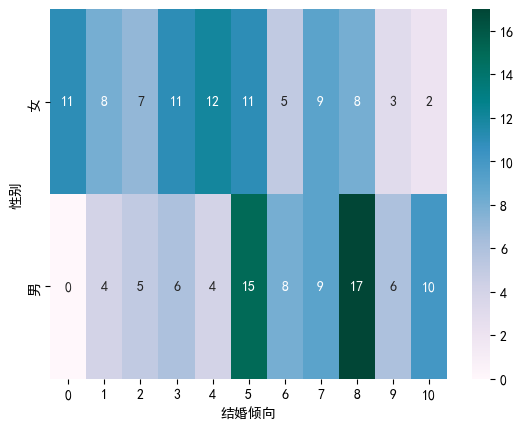

In [10]:
ct1=pd.crosstab(data['性别'],data['结婚倾向'])
sns.heatmap(ct1,annot=True,cmap='PuBuGn')

数量统计结果：男生的结婚倾向普遍比较高，集中在6-10的范围内，也有较多男生对是否要结婚持中立态度；女生的结婚倾向普遍比较低，集中在1-4的范围内，结婚意向特别高的女生基本上寥寥无几。这说明女生对结婚方面可能顾虑会比较重，对婚姻风险的担忧可能比男生大

但是，由于填写问卷的男女生数量不一样，上述分析并不能很好地体现男女的结婚倾向差异，因为人数多会导致颜色深，就会感觉男生那边普遍比女生颜色要深。如果要统计每个性别中不同结婚意愿人数占总人数的比例，那么需要如下处理

#### 按比例统计

In [11]:
# 使用groupby方法统计每个性别对应的不同结婚倾向值出现的次数
counts=data.groupby('性别')['结婚倾向'].value_counts()
# 为了避免部分值为0的部分被忽略，将索引补上
sex_values=['男','女']
val_values=[0,1,2,3,4,5,6,7,8,9,10]
index = pd.MultiIndex.from_product([sex_values, val_values], names=['性别', '结婚倾向'])
counts=counts.reindex(index,fill_value=0)
counts.head()

性别  结婚倾向
男   0       0
    1       4
    2       5
    3       6
    4       4
Name: 结婚倾向, dtype: int64

In [12]:
# 计算每个性别对应的不同结婚倾向出现的比例
propertions=counts.groupby(level=0,group_keys=False).apply(lambda x:x/x.sum())
propertions.head()

性别  结婚倾向
男   0       0.000000
    1       0.047619
    2       0.059524
    3       0.071429
    4       0.047619
Name: 结婚倾向, dtype: float64

In [13]:
# 将比例计算后的结果重新转化为Dataframe
data0=pd.DataFrame(propertions)
data0.columns=['比例']
data0=data0.reset_index()
data0.head()

,性别,结婚倾向,比例
0,男,0,0.000000
1,男,1,0.047619
2,男,2,0.059524
3,男,3,0.071429
4,男,4,0.047619


<AxesSubplot:xlabel='结婚倾向', ylabel='性别'>

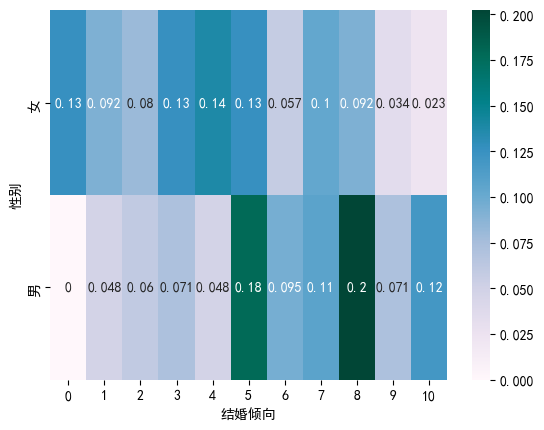

In [14]:
ct2=data0.pivot(index='性别',columns='结婚倾向',values='比例')
sns.heatmap(ct2,annot=True,cmap='PuBuGn')

上面这张图是男/女性不同结婚倾向占填问卷男女性总数的百分比

从比例中就很容易看出来，我们前面按数量统计下的结论确实是具有正确性的（实际上是因为填写问卷的男生和女生数量相差不大）。总的结论概括如下：

**女生的结婚倾向普遍较低，男生的结婚倾向普遍较高，但也有较多男生对婚姻持中立态度。总体来看，男生的结婚意愿明显比女生要强烈，但大学生总体对于婚姻的意愿并不是那么高，没有存在“婚姻是必须的”这种想法**

为什么会这样？到底是什么风险导致了大学生普遍不想结婚？我们接着往下看

### 认为婚后男女风险大小和自身性别的关系

#### 方差分析

In [15]:
f_value,p_value=f_oneway(data[data['性别']=='男']['风险比较'],
                         data[data['性别']=='女']['风险比较'])
print('F =',f_value)
print('P =',p_value)

F = 76.65775101275135
P = 2.0338169337094904e-15


可以看到，显著性水平P的值小于0.05，这意味着男女对于婚后风险比较具有明显差异

#### 按数量统计

和上面一样，首先进行一个单纯的数量上的统计

<AxesSubplot:xlabel='风险比较', ylabel='性别'>

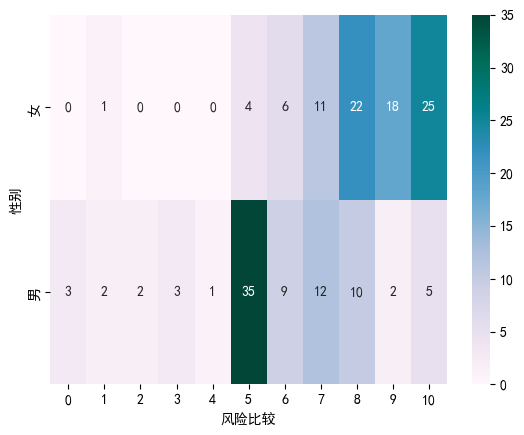

In [16]:
ct3=pd.crosstab(data['性别'],data['风险比较'])
sns.heatmap(ct3,annot=True,cmap='PuBuGn')

从数量上看，结果非常的惊人：大量的男生都认为男女婚后风险平等，但女生普遍认为婚后风险女性比男性大得多。导致这种数据结果的可能性有两个，一是男生偷懒，发现这道题填5就可以少做后面几题，所以干脆直接填5算了；而女生就相对比较认真负责，想要通过这份问卷表达真实想法。二是男生真的觉得婚后男女风险确实是平等的，而女生大多觉得女性的婚后风险比男生大得多。目前我们暂定为第二种情况，接着往下分析

同样，由于男女生填问卷的人数不同，单纯的数量不能直接体现出婚后男女风险大小和自身性别的关系。还是需要转成比例

#### 按比例统计

In [17]:
# 使用groupby方法统计每个性别对应的不同风险比较值出现的次数
counts=data.groupby('性别')['风险比较'].value_counts()
# 为了避免部分值为0的部分被忽略而在图上出现缺口，将索引补上
sex_values=['男','女']
val_values=[0,1,2,3,4,5,6,7,8,9,10]
index = pd.MultiIndex.from_product([sex_values, val_values], names=['性别', '风险比较'])
counts=counts.reindex(index,fill_value=0)
counts.head()

性别  风险比较
男   0       3
    1       2
    2       2
    3       3
    4       1
Name: 风险比较, dtype: int64

In [18]:
# 计算每个性别对应的不同风险比较出现的比例
propertions=counts.groupby(level=0,group_keys=False).apply(lambda x:x/x.sum())
propertions.head()

性别  风险比较
男   0       0.035714
    1       0.023810
    2       0.023810
    3       0.035714
    4       0.011905
Name: 风险比较, dtype: float64

In [19]:
# 将比例计算后的结果重新转化为Dataframe
data0=pd.DataFrame(propertions)
data0.columns=['比例']
data0=data0.reset_index()
data0.head()

,性别,风险比较,比例
0,男,0,0.035714
1,男,1,0.023810
2,男,2,0.023810
3,男,3,0.035714
4,男,4,0.011905


<AxesSubplot:xlabel='风险比较', ylabel='性别'>

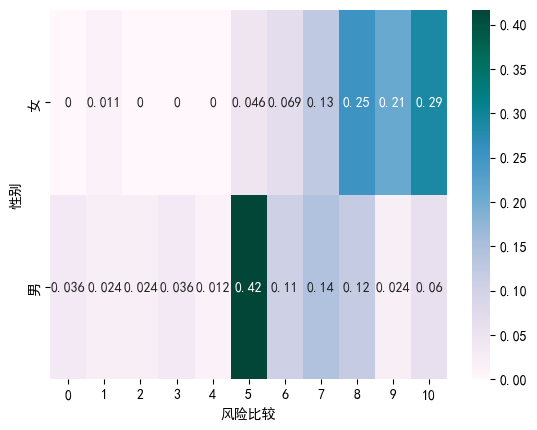

In [20]:
ct4=data0.pivot(index='性别',columns='风险比较',values='比例')
sns.heatmap(ct4,annot=True,cmap='PuBuGn')

我们假设每一份问卷都是有效问卷，那么可以得出以下结论：

**1.男生普遍觉得男女婚后风险相同，但女生普遍觉得婚后女性风险大**

2.男生出现这种思维的可能性一方面是对女生生理方面的不了解，另一方面可能是缺乏对婚后生活的正确认识，或者过分的认为“男女平等”

3.女生觉得婚后女性风险大可能会受到家庭教育或自身观念进步的影响，比如家庭对于女生恋爱和婚姻的有关意见等、女生从小受到的性教育等，让女生觉得自己容易成为弱势方而承受更多的婚姻风险

那么，男生和女生分别在意的风险点在哪里呢？我们接着往下看

#### 风险因素统计

In [21]:
# 统计因素用的包
from collections import Counter

在统计各种原因的数量的时候，为了输出图表美观，将“其他”后面的具体描述去掉，同时将括号里的备注去掉

In [22]:
# 复制一份数据
datas=data.copy()
datas['男性风险大的原因'] = datas['男性风险大的原因'].apply(lambda x: ['其他' if i.startswith('其他') else i for i in x])
datas['女性风险大的原因'] = datas['女性风险大的原因'].apply(lambda x: ['其他' if i.startswith('其他') else i for i in x])
datas['女性风险大的原因'] = datas['女性风险大的原因'].apply(lambda x: ['职业女性观念冲突风险' if i=='职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）' else i for i in x])
datas['女性风险大的原因'] = datas['女性风险大的原因'].apply(lambda x: ['身体健康风险' if i=='身体健康风险（针对一些重大疾病）' else i for i in x])

datas.head()

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分
0,19,男,大二,异性恋,5,无感,10,"[家庭妇女的心理困境风险, 身体健康风险, 婚姻满意度低的风险, 对方出轨风险]",[],15
1,18,男,大一,异性恋,6,(空),7,"[家庭妇女的心理困境风险, 职业女性观念冲突风险]",[],13
2,23,女,硕士研究生,异性恋,6,(空),9,"[产后抑郁风险, 职业女性观念冲突风险, 婚姻满意度低的风险]",[],15
3,19,女,大二,异性恋,7,(空),9,"[家庭妇女的心理困境风险, 身体健康风险, 产后抑郁风险, 职业女性观念冲突风险, 婚姻满意...",[],16
4,19,女,大二,异性恋,4,(空),10,"[家庭妇女的心理困境风险, 身体健康风险, 产后抑郁风险, 职业女性观念冲突风险]",[],14


这个风险因素的统计应该把男女分开

In [23]:
data_male=datas[datas['性别']=='男']
data_female=datas[datas['性别']=='女']
data_female.head()

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分
2,23,女,硕士研究生,异性恋,6,(空),9,"[产后抑郁风险, 职业女性观念冲突风险, 婚姻满意度低的风险]",[],15
3,19,女,大二,异性恋,7,(空),9,"[家庭妇女的心理困境风险, 身体健康风险, 产后抑郁风险, 职业女性观念冲突风险, 婚姻满意...",[],16
4,19,女,大二,异性恋,4,(空),10,"[家庭妇女的心理困境风险, 身体健康风险, 产后抑郁风险, 职业女性观念冲突风险]",[],14
9,20,女,大三,异性恋,10,(空),9,"[家庭妇女的心理困境风险, 身体健康风险, 产后抑郁风险, 职业女性观念冲突风险, 对方出轨风险]",[],19
12,21,女,大二,异性恋,6,(空),6,"[家庭妇女的心理困境风险, 产后抑郁风险]",[],12


在此基础上，还需要把认为男性风险大的和认为女性风险大的分开，将数据拆成四份

In [24]:
# 变量命名：下划线前面的表示自身性别，下划线后面的表示认为哪个风险大
male_male=data_male[data_male['风险比较']<5]
male_female=data_male[data_male['风险比较']>5]
female_male=data_female[data_female['风险比较']<5]
female_female=data_female[data_female['风险比较']>5]
male_male.head()

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分
10,20,男,大二,泛性恋,4,(空),3,[],"[经济压力风险, 家庭与工作平衡风险, 双方父母养老风险]",7
31,22,男,大四,异性恋,8,儒家观点认为家庭是社会的基本单位,1,[],"[经济压力风险, 家庭与工作平衡风险, 对方出轨风险, 双方父母养老风险, 失业风险, 其他]",9
53,20,男,大二,异性恋,4,没有时间经营爱情与家庭,0,[],"[经济压力风险, 家庭与工作平衡风险, 双方父母养老风险, 失业风险, 婚姻满意度风险]",4
57,20,男,大二,同性恋,2,(空),2,[],"[经济压力风险, 家庭与工作平衡风险, 对方出轨风险, 双方父母养老风险, 生育带来的抑郁风...",4
79,19,男,大一,异性恋,1,(空),1,[],"[经济压力风险, 对方出轨风险, 婚姻满意度风险]",2


男性认为男性风险大的原因统计

Text(0.5, 1.0, '男性认为婚后男性风险大的原因统计')

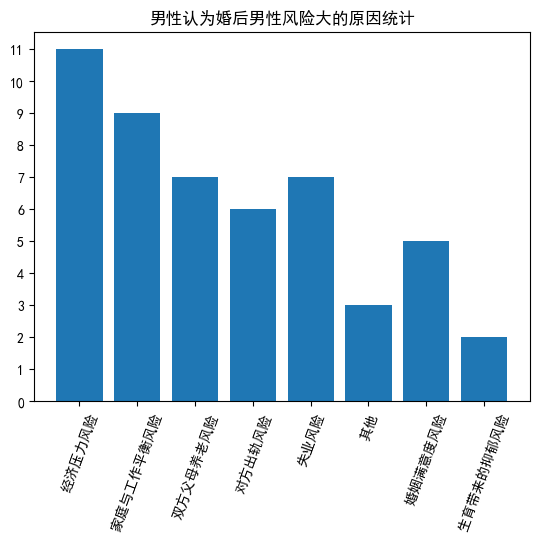

In [25]:
male_male_list=[ele for array in male_male['男性风险大的原因'].tolist() for ele in array]
male_male_dict=Counter(male_male_list)
male_male_result=dict(male_male_dict)
keys=male_male_result.keys()
values=male_male_dict.values()
fig,ax=plt.subplots(1,1)
ax.bar(keys,values)
ax.set_xticks(list(keys))
ax.set_xticklabels(labels=keys,rotation=70)
# 如果以后问卷多了坐标轴刻度太密，调整下面range里面的第三个参数
ax.set_yticks([i for i in range(0,max(values)+1,1)])
ax.set_title('男性认为婚后男性风险大的原因统计')

男性认为女性风险大的原因统计

Text(0.5, 1.0, '男性认为婚后女性风险大的原因统计')

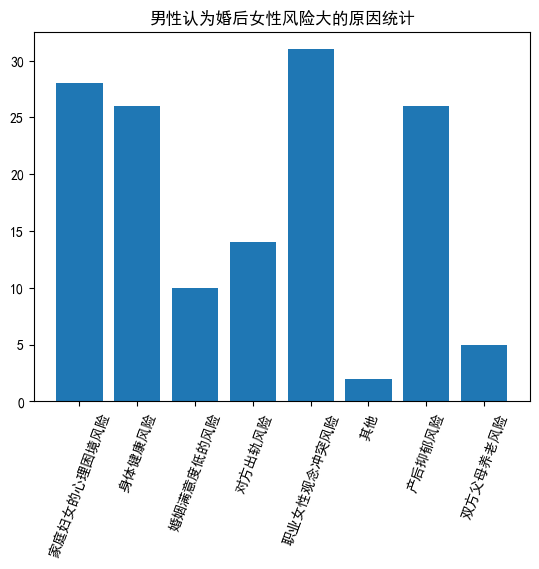

In [26]:
male_female_list=[ele for array in male_female['女性风险大的原因'].tolist() for ele in array]
male_female_dict=Counter(male_female_list)
male_female_result=dict(male_female_dict)
keys=male_female_result.keys()
values=male_female_dict.values()
fig,ax=plt.subplots(1,1)
ax.bar(keys,values)
ax.set_xticks(list(keys))
ax.set_xticklabels(labels=keys,rotation=70)
# 如果以后问卷多了坐标轴刻度太密，调整下面range里面的第三个参数
ax.set_yticks([i for i in range(0,max(values)+1,5)])
ax.set_title('男性认为婚后女性风险大的原因统计')

女性认为男性风险大的原因统计

Text(0.5, 1.0, '女性认为婚后男性风险大的原因统计')

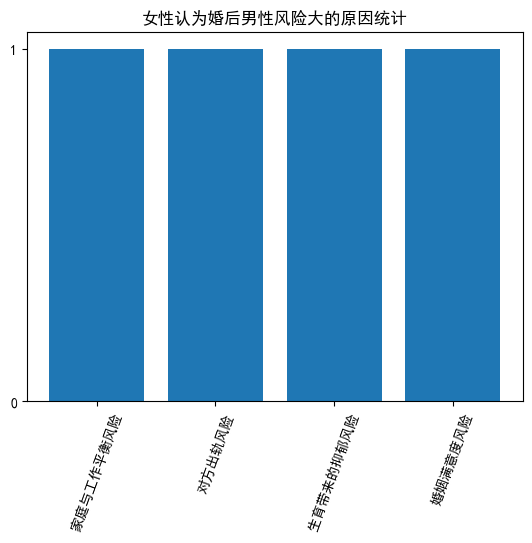

In [27]:
female_male_list=[ele for array in female_male['男性风险大的原因'].tolist() for ele in array]
female_male_dict=Counter(female_male_list)
female_male_result=dict(female_male_dict)
keys=female_male_result.keys()
values=female_male_dict.values()
fig,ax=plt.subplots(1,1)
ax.bar(keys,values)
ax.set_xticks(list(keys))
ax.set_xticklabels(labels=keys,rotation=70)
# 如果以后问卷多了坐标轴刻度太密，调整下面range里面的第三个参数
ax.set_yticks([i for i in range(0,max(values)+1,1)])
ax.set_title('女性认为婚后男性风险大的原因统计')

女性认为女性风险大的原因统计

Text(0.5, 1.0, '女性认为婚后女性风险大的原因统计')

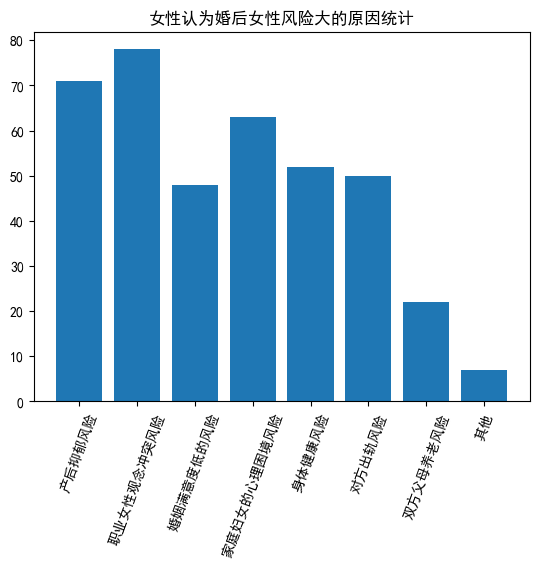

In [28]:
female_female_list=[ele for array in female_female['女性风险大的原因'].tolist() for ele in array]
female_female_dict=Counter(female_female_list)
female_female_result=dict(female_female_dict)
keys=female_female_result.keys()
values=female_female_dict.values()
fig,ax=plt.subplots(1,1)
ax.bar(keys,values)
ax.set_xticks(list(keys))
ax.set_xticklabels(labels=keys,rotation=70)
# 如果以后问卷多了坐标轴刻度太密，调整下面range里面的第三个参数
ax.set_yticks([i for i in range(0,max(values)+10,10)])
ax.set_title('女性认为婚后女性风险大的原因统计')

男生：84；女生：87

将这四张图结合起来，我们可以发现：

男生认为的男性风险：结婚后的经济压力和工作压力，工作和家庭的平衡（10人左右）

男生认为的女性风险：职业女性观念冲突，家庭妇女的心理背景，身体健康和产后健康（27人左右）

女生认为的男性风险：家庭与工作的平衡，对方出轨，生育带来的抑郁（男生有这个选项就离谱hhh），婚姻满意度（各1人）

女生认为的女性风险：职业女性观念冲突，产后抑郁风险（75人左右）

由此可见，为什么女生普遍觉得女性风险大？因为女生对于家庭和工作，家庭地位，以及怀孕后的健康方面担忧极大，这可能是目前社会上各种关于孕妇的负面消息导致的（例如产假的负面消息等等），另外还有一部分关于提高女性家庭地位的宣传。大量的女生站在自身的角度，普遍认为女性婚后需要同时面对家庭、工作、怀孕等身心健康和生活问题，同时还需要在家庭内获取一定的地位，而男性只需要承担事业风险，女性的风险理所应当比男性大得多。而男生则主要将风险定位在事业上，尤其是工作压力和生活压力，自己能不能支撑起整个家庭等，将自己的定位放在家庭的角度，认为自己支撑整个家庭需要花费的精力比女生多得多。另外，对于女性的这些风险，男生很多也能够认识到并有所理解，但女生几乎很难理解男性的婚后压力——女生基本觉得男性婚后没有压力，除非有出轨问题，很少觉得男生的事业压力很重。这也是女生认为婚后女性风险大的主要原因。

总的结论：**男生能够同时认识到男性和女性的婚后压力，认为自己的事业压力和女生的生育压力等同，两者共同分担家庭责任；女生认为自己生育和事业的矛盾较大，在家庭中的地位还要有所提升，比男生的事业压力大得多，难以理解男生的事业压力，普遍认为自己的婚后压力远高于男生**

### 异性恋和同性恋者对于结婚意愿和婚后风险大小的认知区别

#### 不同性取向统计

In [29]:
# 将性取向重新分类，分为异性恋和同性恋还有其他。为此制作一份数据拷贝，避免破坏源数据
datax=data.copy()
datax.loc[(datax['性取向']!='同性恋') & (datax['性取向']!='异性恋'),['性取向']]='其他'
datax.head()

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分
0,19,男,大二,异性恋,5,无感,10,"[家庭妇女的心理困境风险, 身体健康风险（针对一些重大疾病）, 婚姻满意度低的风险, 对方出...",[],15
1,18,男,大一,异性恋,6,(空),7,"[家庭妇女的心理困境风险, 职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）]",[],13
2,23,女,硕士研究生,异性恋,6,(空),9,"[产后抑郁风险, 职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）, 婚姻...",[],15
3,19,女,大二,异性恋,7,(空),9,"[家庭妇女的心理困境风险, 身体健康风险（针对一些重大疾病）, 产后抑郁风险, 职业女性观念...",[],16
4,19,女,大二,异性恋,4,(空),10,"[家庭妇女的心理困境风险, 身体健康风险（针对一些重大疾病）, 产后抑郁风险, 职业女性观念...",[],14


统计一下异性恋、同性恋、其他性取向的人数

In [30]:
count1=(datax['性取向']=='异性恋').sum()
count2=(datax['性取向']=='同性恋').sum()
count3=(datax['性取向']=='其他').sum()
print('异性恋：',count1)
print('同性恋：',count2)
print('其他：',count3)

异性恋： 137
同性恋： 5
其他： 29


这人数差异太大，直接统计数据就没啥意义了。直接按比例算

#### 方差分析

In [31]:
f_value1,p_value1=f_oneway(datax[datax['性取向']=='同性恋']['结婚倾向'],datax[datax['性取向']=='异性恋']['结婚倾向'],datax[datax['性取向']=='其他']['结婚倾向'])
f_value2,p_value2=f_oneway(datax[datax['性取向']=='同性恋']['风险比较'],datax[datax['性取向']=='异性恋']['风险比较'],datax[datax['性取向']=='其他']['风险比较'])

print('结婚倾向的 F =',f_value1)
print('结婚倾向的 P =',p_value1)
print('风险比较的 F =',f_value2)
print('风险比较的 P =',p_value2)

结婚倾向的 F = 9.364254898676265
结婚倾向的 P = 0.00013940765947790637
风险比较的 F = 1.6140459499666158
风险比较的 P = 0.20215208684669234


从方差分析的结果中可以体现出，从性取向的角度进行分析，结婚倾向的P值小于0.05，也就是说不同性取向对于结婚倾向的差异较为显著。**但是不同性取向的人对于婚后男女风险比较的差异性明显较小。** 这个可以接下来做进一步分析

#### 按比例统计

下面对两个变量同时处理，第一个是结婚倾向，第二个是风险比较

In [32]:
counts1=datax.groupby('性取向')['结婚倾向'].value_counts()
sex_values=['异性恋','同性恋','其他']
val_values=[0,1,2,3,4,5,6,7,8,9,10]
index = pd.MultiIndex.from_product([sex_values, val_values], names=['性取向', '结婚倾向'])
counts1=counts1.reindex(index,fill_value=0)
counts1.head()

性取向  结婚倾向
异性恋  0        6
     1        9
     2        7
     3       10
     4       13
Name: 结婚倾向, dtype: int64

In [33]:
counts2=datax.groupby('性取向')['风险比较'].value_counts()
sex_values=['异性恋','同性恋','其他']
val_values=[0,1,2,3,4,5,6,7,8,9,10]
index = pd.MultiIndex.from_product([sex_values, val_values], names=['性取向', '风险比较'])
counts2=counts2.reindex(index,fill_value=0)
counts2.head()

性取向  风险比较
异性恋  0       3
     1       2
     2       0
     3       2
     4       1
Name: 风险比较, dtype: int64

计算比例

In [34]:
propertions1=counts1.groupby(level=0,group_keys=False).apply(lambda x:x/x.sum())
propertions1.head()

性取向  结婚倾向
异性恋  0       0.043796
     1       0.065693
     2       0.051095
     3       0.072993
     4       0.094891
Name: 结婚倾向, dtype: float64

In [35]:
propertions2=counts2.groupby(level=0,group_keys=False).apply(lambda x:x/x.sum())
propertions2.head()

性取向  风险比较
异性恋  0       0.021898
     1       0.014599
     2       0.000000
     3       0.014599
     4       0.007299
Name: 风险比较, dtype: float64

构建数据表

In [36]:
data1=pd.DataFrame(propertions1)
data1.columns=['比例']
data1=data1.reset_index()
data1.head()

,性取向,结婚倾向,比例
0,异性恋,0,0.043796
1,异性恋,1,0.065693
2,异性恋,2,0.051095
3,异性恋,3,0.072993
4,异性恋,4,0.094891


In [37]:
data2=pd.DataFrame(propertions2)
data2.columns=['比例']
data2=data2.reset_index()
data2.head()

,性取向,风险比较,比例
0,异性恋,0,0.021898
1,异性恋,1,0.014599
2,异性恋,2,0.000000
3,异性恋,3,0.014599
4,异性恋,4,0.007299


绘图

<AxesSubplot:xlabel='结婚倾向', ylabel='性取向'>

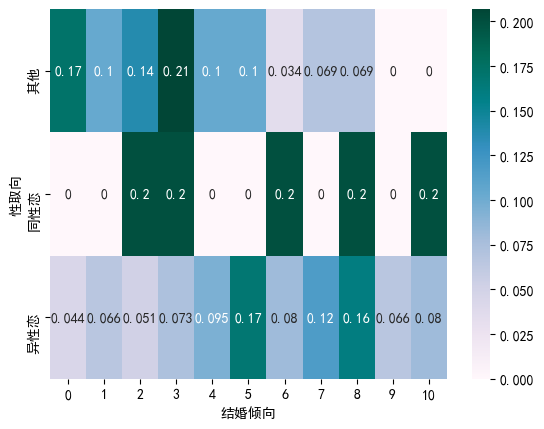

In [38]:
ct5=data1.pivot(index='性取向',columns='结婚倾向',values='比例')
sns.heatmap(ct5,annot=True,cmap='PuBuGn')

由于同性恋人数实在太少，个人觉得这个图很难说明什么东西。但相对来说还是想要结婚的人多一点？

异性恋者对于结婚的意愿相对来说比较多样化。有较多认为中立的人，也有较多想要结婚的人。相对来说，不想结婚的人少一些，总体偏向于想要结婚

其他性取向者的结婚意愿普遍较低。这也比较好理解，因为自己性取向的原因，对于结婚的事情可能会不确定

<AxesSubplot:xlabel='风险比较', ylabel='性取向'>

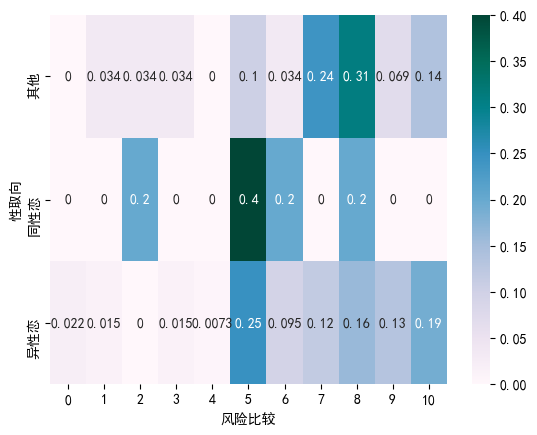

In [39]:
ct6=data2.pivot(index='性取向',columns='风险比较',values='比例')
sns.heatmap(ct6,annot=True,cmap='PuBuGn')

同性恋者普遍认为婚后男女风险平等。不过还是觉得女生风险大的多一些

异性恋者普遍觉得女性婚后风险大。这可能是异性恋者的恋爱经历告诉他们，谈恋爱时女生还是处于弱势一方，要学会理解女生，对女生有所照顾，了解女生在恋爱或婚姻中的地位和作用，两个人才能比较和睦稳定地生活下去

其他性取向者也普遍觉得女性婚后风险大。这说明他们虽然性取向较为特殊，但对于女性的弱势地位还是认可的

#### 婚后风险大小的原因统计

和前面一样，在统计各种原因的数量的时候，为了输出图表美观，将“其他”后面的具体描述去掉，同时将括号里的备注去掉

In [40]:
datax['男性风险大的原因'] = datax['男性风险大的原因'].apply(lambda x: ['其他' if i.startswith('其他') else i for i in x])
datax['女性风险大的原因'] = datax['女性风险大的原因'].apply(lambda x: ['其他' if i.startswith('其他') else i for i in x])
datax['女性风险大的原因'] = datax['女性风险大的原因'].apply(lambda x: ['职业女性观念冲突风险' if i=='职业女性观念冲突风险（例如：家务分工观念风险和家庭事物决策权风险）' else i for i in x])
datax['女性风险大的原因'] = datax['女性风险大的原因'].apply(lambda x: ['身体健康风险' if i=='身体健康风险（针对一些重大疾病）' else i for i in x])

和前面一样，把同性恋、异性恋和其他分开

In [41]:
datax_hom=datax[datax['性取向']=='同性恋']
datax_het=datax[datax['性取向']=='异性恋']
datax_oth=datax[datax['性取向']=='其他']
datax_hom.head()

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分
22,18,男,大一,同性恋,3,(空),5,[],[],8
57,20,男,大二,同性恋,2,(空),2,[],"[经济压力风险, 家庭与工作平衡风险, 对方出轨风险, 双方父母养老风险, 生育带来的抑郁风...",4
94,18,男,大一,同性恋,10,安全感,8,"[产后抑郁风险, 职业女性观念冲突风险]",[],18
132,18,男,大二,同性恋,6,择一人终老嘛,5,[],[],11
161,59,男,博士研究生,同性恋,8,sex,6,"[家庭妇女的心理困境风险, 身体健康风险, 产后抑郁风险, 职业女性观念冲突风险, 婚姻满意...",[],14


分成六组：同性恋男性风险大，同性恋女性风险大，异性恋男性风险大，异性恋女性风险大，其他男性风险大，其他女性风险大

In [42]:
datax_hom_male=datax_hom[datax_hom['风险比较']<5]
datax_hom_female=datax_hom[datax_hom['风险比较']>5]
datax_het_male=datax_het[datax_het['风险比较']<5]
datax_het_female=datax_het[datax_het['风险比较']>5]
datax_oth_male=datax_oth[datax_oth['风险比较']<5]
datax_oth_female=datax_oth[datax_oth['风险比较']>5]
datax_hom_male.head()

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分
57,20,男,大二,同性恋,2,(空),2,[],"[经济压力风险, 家庭与工作平衡风险, 对方出轨风险, 双方父母养老风险, 生育带来的抑郁风...",4


同性恋男性风险大因素统计

Text(0.5, 1.0, '同性恋者认为婚后男性风险大的原因统计')

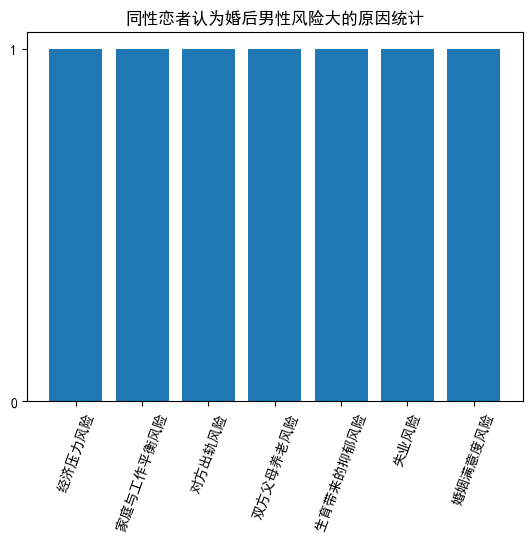

In [43]:
hom_male_list=[ele for array in datax_hom_male['男性风险大的原因'].tolist() for ele in array]
hom_male_dict=Counter(hom_male_list)
hom_male_result=dict(hom_male_dict)
keys=hom_male_result.keys()
values=hom_male_dict.values()
fig,ax=plt.subplots(1,1)
ax.bar(keys,values)
ax.set_xticks(list(keys))
ax.set_xticklabels(labels=keys,rotation=70)
# 如果以后问卷多了坐标轴刻度太密，调整下面range里面的第三个参数
ax.set_yticks([i for i in range(0,max(values)+1,1)])
ax.set_title('同性恋者认为婚后男性风险大的原因统计')

同性恋女性风险大因素统计

Text(0.5, 1.0, '同性恋者认为婚后女性风险大的原因统计')

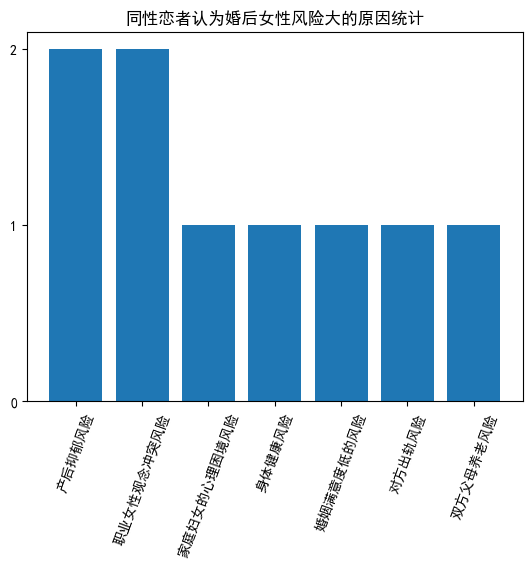

In [44]:
hom_female_list=[ele for array in datax_hom_female['女性风险大的原因'].tolist() for ele in array]
hom_female_dict=Counter(hom_female_list)
hom_female_result=dict(hom_female_dict)
keys=hom_female_result.keys()
values=hom_female_dict.values()
fig,ax=plt.subplots(1,1)
ax.bar(keys,values)
ax.set_xticks(list(keys))
ax.set_xticklabels(labels=keys,rotation=70)
# 如果以后问卷多了坐标轴刻度太密，调整下面range里面的第三个参数
ax.set_yticks([i for i in range(0,max(values)+1,1)])
ax.set_title('同性恋者认为婚后女性风险大的原因统计')

异性恋男性风险大因素统计

Text(0.5, 1.0, '异性恋者认为婚后男性风险大的原因统计')

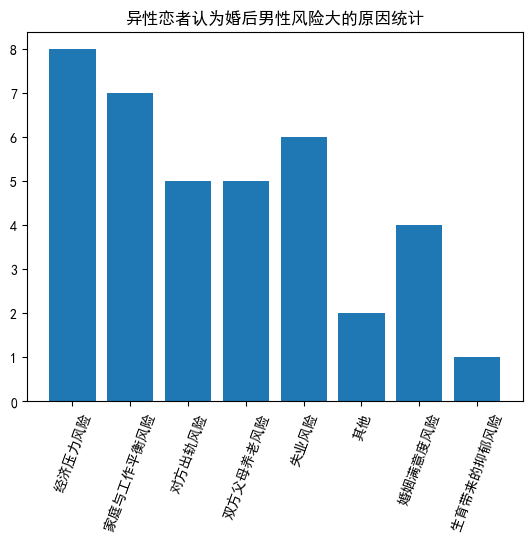

In [45]:
het_male_list=[ele for array in datax_het_male['男性风险大的原因'].tolist() for ele in array]
het_male_dict=Counter(het_male_list)
het_male_result=dict(het_male_dict)
keys=het_male_result.keys()
values=het_male_dict.values()
fig,ax=plt.subplots(1,1)
ax.bar(keys,values)
ax.set_xticks(list(keys))
ax.set_xticklabels(labels=keys,rotation=70)
# 如果以后问卷多了坐标轴刻度太密，调整下面range里面的第三个参数
ax.set_yticks([i for i in range(0,max(values)+1,1)])
ax.set_title('异性恋者认为婚后男性风险大的原因统计')

异性恋女性风险大因素统计

Text(0.5, 1.0, '异性恋者认为婚后女性风险大的原因统计')

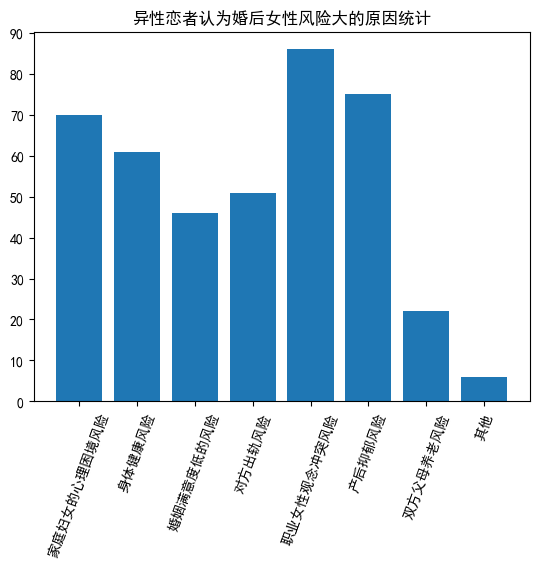

In [46]:
het_female_list=[ele for array in datax_het_female['女性风险大的原因'].tolist() for ele in array]
het_female_dict=Counter(het_female_list)
het_female_result=dict(het_female_dict)
keys=het_female_result.keys()
values=het_female_dict.values()
fig,ax=plt.subplots(1,1)
ax.bar(keys,values)
ax.set_xticks(list(keys))
ax.set_xticklabels(labels=keys,rotation=70)
# 如果以后问卷多了坐标轴刻度太密，调整下面range里面的第三个参数
ax.set_yticks([i for i in range(0,max(values)+10,10)])
ax.set_title('异性恋者认为婚后女性风险大的原因统计')

其他性取向者男性风险大因素统计

Text(0.5, 1.0, '其他性取向者认为婚后男性风险大的原因统计')

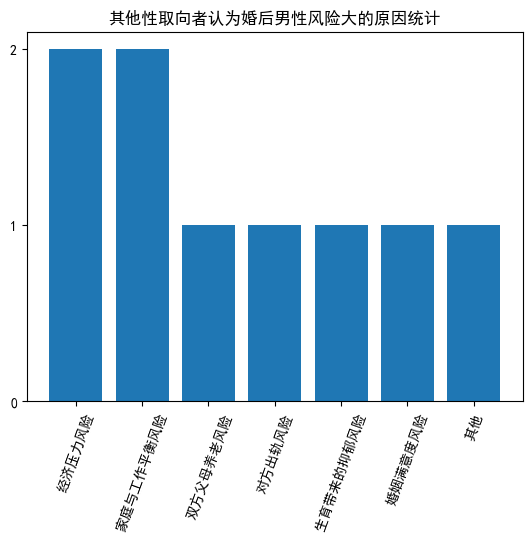

In [47]:
oth_male_list=[ele for array in datax_oth_male['男性风险大的原因'].tolist() for ele in array]
oth_male_dict=Counter(oth_male_list)
oth_male_result=dict(oth_male_dict)
keys=oth_male_result.keys()
values=oth_male_dict.values()
fig,ax=plt.subplots(1,1)
ax.bar(keys,values)
ax.set_xticks(list(keys))
ax.set_xticklabels(labels=keys,rotation=70)
# 如果以后问卷多了坐标轴刻度太密，调整下面range里面的第三个参数
ax.set_yticks([i for i in range(0,max(values)+1,1)])
ax.set_title('其他性取向者认为婚后男性风险大的原因统计')

其他性取向者女性风险大因素统计

Text(0.5, 1.0, '其他性取向者认为婚后女性风险大的原因统计')

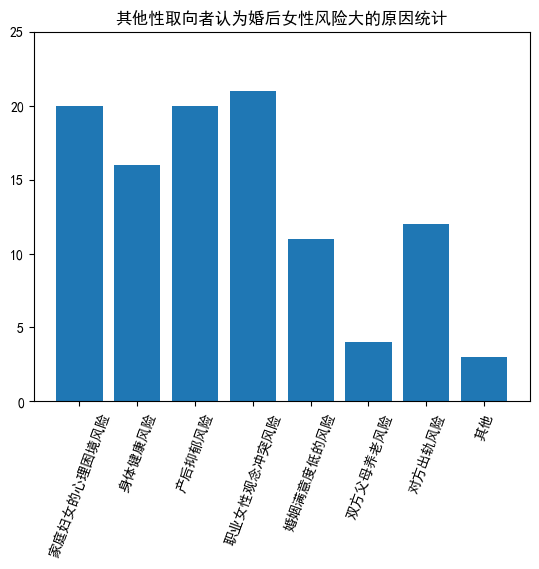

In [48]:
oth_female_list=[ele for array in datax_oth_female['女性风险大的原因'].tolist() for ele in array]
oth_female_dict=Counter(oth_female_list)
oth_female_result=dict(oth_female_dict)
keys=oth_female_result.keys()
values=oth_female_dict.values()
fig,ax=plt.subplots(1,1)
ax.bar(keys,values)
ax.set_xticks(list(keys))
ax.set_xticklabels(labels=keys,rotation=70)
# 如果以后问卷多了坐标轴刻度太密，调整下面range里面的第三个参数
ax.set_yticks([i for i in range(0,max(values)+5,5)])
ax.set_title('其他性取向者认为婚后女性风险大的原因统计')

异性恋：137；同性恋：5；其他：29

同性恋者认为的男性风险：经济、健康、养老、出轨、失业等都有，但只有1人

同性恋者认为的女性风险：产后抑郁，职业女性观念冲突（2人）

异性恋者认为的男性风险：经济压力，失业，家庭与工作的平衡（7-8人）

异性恋者认为的女性风险：职业女性观念冲突，产后抑郁，家庭妇女心理因素（70-80人）

其他性取向者认为的男性风险：经济压力，家庭与工作平衡（2人）

其他性取向者认为的女性风险：职业女性观念冲突，产后抑郁，家庭妇女心理因素（20人）

可以看到，无论是异性恋者还是同性恋者，职业女性观念冲突、产后抑郁这两大因素均位居女性风险大原因榜首。由此可见，这两个问题已经成为当今社会的普遍问题，受到广泛重视。不管受访者的性取向是什么，只要认为女性风险大的，基本上都会觉得风险的主要来源是这两个点。这说明目前社会普遍认为女性的弱势点就是家庭分工观念风险和家庭事务决策风险，以及怀孕带来的心理问题。这与当今社会女性家庭地位的提高是密不可分的。同时我们也可以发现，男性的风险还是集中在经济压力、就业压力、家庭与工作的平衡等事业方面。但除了同性恋者为同性考虑的多之外，异性恋者和其他性取向者都普遍认为男性的这点压力完全比不上女性在家庭观念、怀孕等方面承担的压力。这也说明了当今社会妇女的现状问题

### 相关分析

#### 数据处理

相关分析只能对数值进行处理。因此，我们需要做如下转变：

性别：男1女0；性取向：异1同-1其他0

In [49]:
# 构造一份数据拷贝，性取向使用三个分类法
df=datax.copy()
df['性别']=df['性别'].map({'男':1,'女':0})
df['性取向']=df['性取向'].map({'异性恋':1,'同性恋':-1,'其他':0})
df.head()

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分
0,19,1,大二,1,5,无感,10,"[家庭妇女的心理困境风险, 身体健康风险, 婚姻满意度低的风险, 对方出轨风险]",[],15
1,18,1,大一,1,6,(空),7,"[家庭妇女的心理困境风险, 职业女性观念冲突风险]",[],13
2,23,0,硕士研究生,1,6,(空),9,"[产后抑郁风险, 职业女性观念冲突风险, 婚姻满意度低的风险]",[],15
3,19,0,大二,1,7,(空),9,"[家庭妇女的心理困境风险, 身体健康风险, 产后抑郁风险, 职业女性观念冲突风险, 婚姻满意...",[],16
4,19,0,大二,1,4,(空),10,"[家庭妇女的心理困境风险, 身体健康风险, 产后抑郁风险, 职业女性观念冲突风险]",[],14


#### 相关系数

这里分别计算性别、性取向和结婚倾向、风险比较的相关系数。由于性别和性取向为文字转值，其相关系数大小会受到转化映射函数的影响（例如男1女0和男100女0显然最后相关系数就会不一样），所以不用在意太多。主要是结婚倾向和风险比较的影响

In [50]:
df[['性别','性取向','风险比较','结婚倾向']].corr()

,性别,性取向,风险比较,结婚倾向
性别,1.000000,0.100432,-0.558615,0.361967
性取向,0.100432,1.000000,0.084263,0.219171
风险比较,-0.558615,0.084263,1.000000,-0.088928
结婚倾向,0.361967,0.219171,-0.088928,1.000000


结婚倾向和风险比较的相关性不大

进行显著性检验。性别和风险比较，性取向和风险比较，性取向和结婚倾向，性别和结婚倾向的显著性检验在前面的方差分析部分已经做过了，这里只做结婚倾向和风险比较的显著性检验

In [51]:
from scipy.stats import pearsonr

corr,p_value=pearsonr(df['结婚倾向'],df['风险比较'])
print('结婚倾向和风险比较的 P =',p_value)

结婚倾向和风险比较的 P = 0.24741742042477846


P的值没有小于0.05，说明结婚倾向和风险比较的关系不显著，对它们进行相关分析没有意义，故这里不再分析

### 回归分析

In [52]:
import statsmodels.api as sm

X=df[['性别','性取向','风险比较']]
Y=df['结婚倾向']

X=sm.add_constant(X)
model=sm.OLS(Y,X).fit()
model.params

const    2.102360
性别       2.400576
性取向      0.984192
风险比较     0.162175
dtype: float64

按照性别$s$：男1女0；性取向$p$：异1同-1其他0；风险比较$t$：0-10进行多元回归分析，得到的回归方程为：$y=2.401s+0.984p+0.162t$。由此可见在影响结婚倾向的三个因素中，性别因素占据主导地位，其次是性取向。风险比较对于结婚倾向的影响并不重要，这在前面的相关分析中也体现出来了

如果把影响因素不大的“风险比较”去掉，再次进行回归分析，得到的结果如下

In [53]:
X=df[['性别','性取向']]
Y=df['结婚倾向']

X=sm.add_constant(X)
model=sm.OLS(Y,X).fit()
model.params

const    3.368696
性别       1.970738
性取向      1.094022
dtype: float64

得到的结果是：$y=1.970s+1.094p$，性别和性取向的参数变化不大。这进一步说明婚后风险的因素对于结婚倾向没有明显影响

## 数据总的统计

### 各数据项总体情况

In [54]:
data.describe()

,年龄,结婚倾向,风险比较,总分
count,171.000000,171.000000,171.000000,171.000000
mean,20.228070,5.181287,7.029240,12.210526
std,3.257665,2.877274,2.319805,3.531723
min,18.000000,0.000000,0.000000,1.000000
25%,19.000000,3.000000,5.000000,10.000000
50%,20.000000,5.000000,7.000000,13.000000
75%,21.000000,8.000000,9.000000,15.000000
max,59.000000,10.000000,10.000000,20.000000


以上是对受访者年龄、结婚倾向、风险比较和总分的总体情况统计，统计量分别为总行数、平均数、标准差、最小值、四分位数、最大值

### 总的婚后风险因素统计

个人还是觉得应当对婚后风险因素做一个总的统计

In [55]:
data_male=datas[datas['风险比较']<5]
data_female=datas[datas['风险比较']>5]
data_male.head()

,年龄,性别,年级,性取向,结婚倾向,结婚理由,风险比较,女性风险大的原因,男性风险大的原因,总分
10,20,男,大二,泛性恋,4,(空),3,[],"[经济压力风险, 家庭与工作平衡风险, 双方父母养老风险]",7
31,22,男,大四,异性恋,8,儒家观点认为家庭是社会的基本单位,1,[],"[经济压力风险, 家庭与工作平衡风险, 对方出轨风险, 双方父母养老风险, 失业风险, 其他]",9
53,20,男,大二,异性恋,4,没有时间经营爱情与家庭,0,[],"[经济压力风险, 家庭与工作平衡风险, 双方父母养老风险, 失业风险, 婚姻满意度风险]",4
57,20,男,大二,同性恋,2,(空),2,[],"[经济压力风险, 家庭与工作平衡风险, 对方出轨风险, 双方父母养老风险, 生育带来的抑郁风...",4
79,19,男,大一,异性恋,1,(空),1,[],"[经济压力风险, 对方出轨风险, 婚姻满意度风险]",2


统计男性风险大的因素

Text(0.5, 1.0, '婚后男性风险大的原因统计')

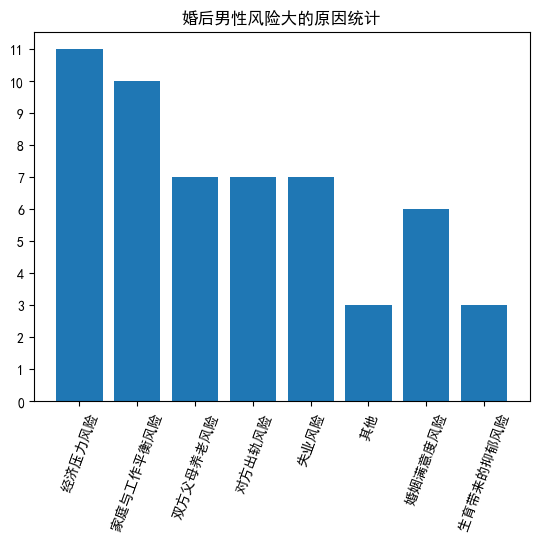

In [56]:
male_list=[ele for array in data_male['男性风险大的原因'].tolist() for ele in array]
male_dict=Counter(male_list)
male_result=dict(male_dict)
keys=male_result.keys()
values=male_dict.values()
fig,ax=plt.subplots(1,1)
ax.bar(keys,values)
ax.set_xticks(list(keys))
ax.set_xticklabels(labels=keys,rotation=70)
# 如果以后问卷多了坐标轴刻度太密，调整下面range里面的第三个参数
ax.set_yticks([i for i in range(0,max(values)+1,1)])
ax.set_title('婚后男性风险大的原因统计')

婚后女性风险大的因素统计

Text(0.5, 1.0, '婚后女性风险大的原因统计')

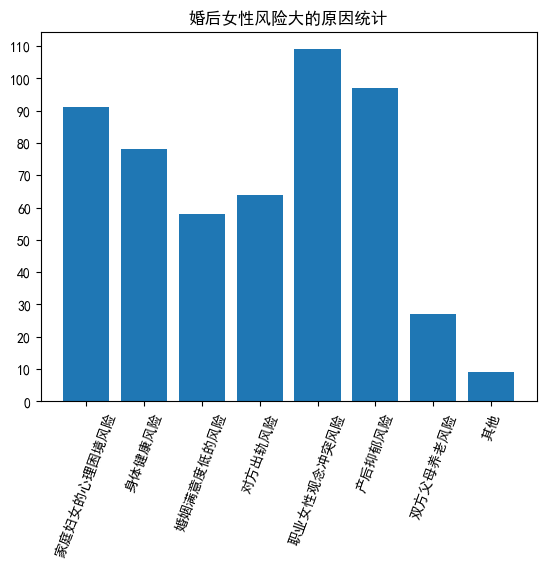

In [57]:
female_list=[ele for array in data_female['女性风险大的原因'].tolist() for ele in array]
female_dict=Counter(female_list)
female_result=dict(female_dict)
keys=female_result.keys()
values=female_dict.values()
fig,ax=plt.subplots(1,1)
ax.bar(keys,values)
ax.set_xticks(list(keys))
ax.set_xticklabels(labels=keys,rotation=70)
# 如果以后问卷多了坐标轴刻度太密，调整下面range里面的第三个参数
ax.set_yticks([i for i in range(0,max(values)+10,10)])
ax.set_title('婚后女性风险大的原因统计')

男性最大的三个风险因素：经济压力，家庭与工作平衡，失业和出轨还有养老并列

女性最大的三个风险因素：职业女性观念冲突，产后抑郁，家庭妇女的心理困难

可见，随着女性社会地位的提高，婚后女性的家庭地位、心理困境和观念变化已经成为当今社会的主要问题。而男性的事业压力虽然比女性大，但其导致的问题在大多数人看来普遍不如女性面对的矛盾。这是有关部门需要注意的

### 词云图

对“风险因素”生成词云图

In [58]:
# 拼接此后
textm=''
for ele in data['男性风险大的原因']:
    if(ele!=['']):
        for s in ele:
            textm+=s

textf=''
for ele in data['女性风险大的原因']:
    if(ele!=['']):
        for s in ele:
            textf+=s

# 调整部分词汇
textm=textm.replace('〖','').replace('〗','').replace('（','').replace('）','').replace('，','').replace('、','').replace('。','')
textf=textf.replace('〖','').replace('〗','').replace('（','').replace('）','').replace('，','').replace('、','').replace('。','')

text=textm+textf
print(text)

经济压力风险家庭与工作平衡风险双方父母养老风险经济压力风险家庭与工作平衡风险对方出轨风险双方父母养老风险失业风险其他社会附加的责任甚至苛责经济压力风险家庭与工作平衡风险双方父母养老风险失业风险婚姻满意度风险经济压力风险家庭与工作平衡风险对方出轨风险双方父母养老风险生育带来的抑郁风险失业风险婚姻满意度风险经济压力风险对方出轨风险婚姻满意度风险家庭与工作平衡风险对方出轨风险生育带来的抑郁风险婚姻满意度风险经济压力风险家庭与工作平衡风险对方出轨风险双方父母养老风险失业风险婚姻满意度风险经济压力风险家庭与工作平衡风险双方父母养老风险失业风险经济压力风险家庭与工作平衡风险对方出轨风险双方父母养老风险生育带来的抑郁风险失业风险婚姻满意度风险其他潜在生命危险经济压力风险其他有不良思想影响伴侣经济压力风险家庭与工作平衡风险经济压力风险家庭与工作平衡风险对方出轨风险失业风险家庭妇女的心理困境风险身体健康风险针对一些重大疾病婚姻满意度低的风险对方出轨风险家庭妇女的心理困境风险职业女性观念冲突风险例如：家务分工观念风险和家庭事物决策权风险产后抑郁风险职业女性观念冲突风险例如：家务分工观念风险和家庭事物决策权风险婚姻满意度低的风险家庭妇女的心理困境风险身体健康风险针对一些重大疾病产后抑郁风险职业女性观念冲突风险例如：家务分工观念风险和家庭事物决策权风险婚姻满意度低的风险对方出轨风险双方父母养老风险家庭妇女的心理困境风险身体健康风险针对一些重大疾病产后抑郁风险职业女性观念冲突风险例如：家务分工观念风险和家庭事物决策权风险家庭妇女的心理困境风险身体健康风险针对一些重大疾病职业女性观念冲突风险例如：家务分工观念风险和家庭事物决策权风险其他被迫性行为和怀孕风险男性特有不良习惯导致的风险二手烟发酒疯等家庭妇女的心理困境风险身体健康风险针对一些重大疾病产后抑郁风险职业女性观念冲突风险例如：家务分工观念风险和家庭事物决策权风险家庭妇女的心理困境风险身体健康风险针对一些重大疾病双方父母养老风险家庭妇女的心理困境风险身体健康风险针对一些重大疾病产后抑郁风险职业女性观念冲突风险例如：家务分工观念风险和家庭事物决策权风险对方出轨风险身体健康风险针对一些重大疾病产后抑郁风险对方出轨风险家庭妇女的心理困境风险产后抑郁风险家庭妇女的心理困境风险身体健康风险针对一些重大疾病职业女性观念冲突风险例如：家务分工观念风险和家

使用词法分析提取出词汇

In [59]:
import jieba

# 停用词表
stop_words = open("stop_words_full.txt",encoding="utf8").read().split("\n")

mtext = ' '.join(jieba.cut(textm))
ftext = ' '.join(jieba.cut(textf))
wtext = ' ' .join(jieba.cut(text))
print(wtext)

Building prefix dict from the default dictionary ...
Loading model from cache C:\Users\zhjw\AppData\Local\Temp\jieba.cache
Loading model cost 0.475 seconds.
Prefix dict has been built successfully.


经济 压力 风险 家庭 与 工作 平衡 风险 双方 父母 养老 风险 经济 压力 风险 家庭 与 工作 平衡 风险 对方 出轨 风险 双方 父母 养老 风险 失业 风险 其他 社会 附加 的 责任 甚至 苛责 经济 压力 风险 家庭 与 工作 平衡 风险 双方 父母 养老 风险 失业 风险 婚姻 满意度 风险 经济 压力 风险 家庭 与 工作 平衡 风险 对方 出轨 风险 双方 父母 养老 风险 生育 带来 的 抑郁 风险 失业 风险 婚姻 满意度 风险 经济 压力 风险 对方 出轨 风险 婚姻 满意度 风险 家庭 与 工作 平衡 风险 对方 出轨 风险 生育 带来 的 抑郁 风险 婚姻 满意度 风险 经济 压力 风险 家庭 与 工作 平衡 风险 对方 出轨 风险 双方 父母 养老 风险 失业 风险 婚姻 满意度 风险 经济 压力 风险 家庭 与 工作 平衡 风险 双方 父母 养老 风险 失业 风险 经济 压力 风险 家庭 与 工作 平衡 风险 对方 出轨 风险 双方 父母 养老 风险 生育 带来 的 抑郁 风险 失业 风险 婚姻 满意度 风险 其他 潜在 生命危险 经济 压力 风险 其他 有 不良 思想 影响 伴侣 经济 压力 风险 家庭 与 工作 平衡 风险 经济 压力 风险 家庭 与 工作 平衡 风险 对方 出轨 风险 失业 风险 家庭妇女 的 心理 困境 风险 身体健康 风险 针对 一些 重大 疾病 婚姻 满意度 低 的 风险 对方 出轨 风险 家庭妇女 的 心理 困境 风险 职业女性 观念 冲突 风险 例如 ： 家务 分工 观念 风险 和 家庭 事物 决策权 风险 产后 抑郁 风险 职业女性 观念 冲突 风险 例如 ： 家务 分工 观念 风险 和 家庭 事物 决策权 风险 婚姻 满意度 低 的 风险 家庭妇女 的 心理 困境 风险 身体健康 风险 针对 一些 重大 疾病 产后 抑郁 风险 职业女性 观念 冲突 风险 例如 ： 家务 分工 观念 风险 和 家庭 事物 决策权 风险 婚姻 满意度 低 的 风险 对方 出轨 风险 双方 父母 养老 风险 家庭妇女 的 心理 困境 风险 身体健康 风险 针对 一些 重大 疾病 产后 抑郁 风险 职业女性 观念 冲突 风险 例如 ： 家务 分工 观念 风险 和 家庭 事物 决策权 风险 家庭妇女 的 心理 困境 风险

生成词云图

In [60]:
from wordcloud import WordCloud
wordcloudm = WordCloud(font_path='msyh.ttc',background_color='white',stopwords=stop_words).generate(mtext)
wordcloudf = WordCloud(font_path='msyh.ttc',background_color='white',stopwords=stop_words).generate(ftext)
wordcloud = WordCloud(font_path='msyh.ttc',background_color='white',stopwords=stop_words).generate(wtext)

男性风险大的词云图

(-0.5, 399.5, 199.5, -0.5)

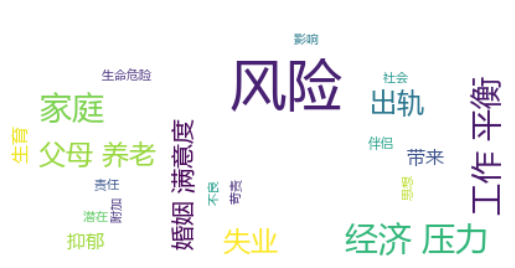

In [61]:
plt.imshow(wordcloudm, interpolation='bilinear')
plt.axis('off')

女性风险大的词云图

(-0.5, 399.5, 199.5, -0.5)

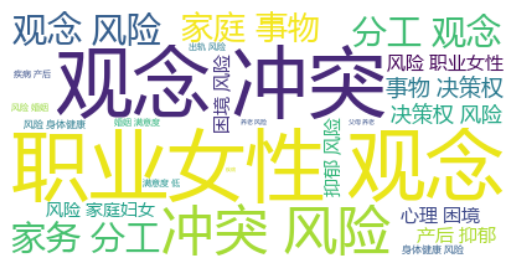

In [62]:
plt.imshow(wordcloudf, interpolation='bilinear')
plt.axis('off')

综合词云图

(-0.5, 399.5, 199.5, -0.5)

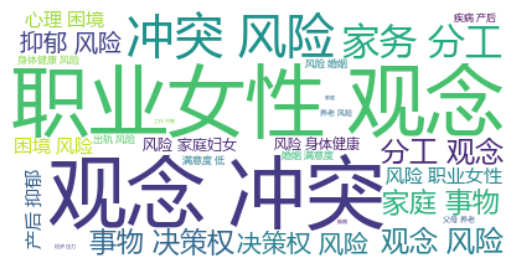

In [63]:
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')